# Practice Lab: Regularization with Ridge, Lasso, and ElasticNet

We are tackling a common problem in Data Science: **Multicollinearity** (when your features are highly correlated with each other) and **Overfitting**. 

To solve this, we will use **Regularization**, which penalizes complex models. You will build and compare four models:
1. Standard Linear Regression (Base Model)
2. Ridge Regression ($L_2$ Penalty)
3. Lasso Regression ($L_1$ Penalty)
4. ElasticNet (Combination of $L_1$ and $L_2$)

### Abalone & The Business Problem
We will use the famous Abalone dataset to predict the age of an abalone (a highly valued marine snail) based on its physical measurements. 

**Why does predicting their age matter?**

Abalones are a premium seafood delicacy, making them vulnerable to overfishing. Strict regulations are in place to ensure abalones are only harvested after they reach a certain age, allowing them time to reproduce. Furthermore, aquaculture farms need to track age to optimize feeding and harvest times for profit. 

Currently, determining an abalone's age is a destructive, expensive, and tedious process: it requires cutting the shell, staining it, and counting the rings under a microscope. **Our goal is to build a Machine Learning model that can predict the age (number of rings) using simple, non-destructive measurements like weight and length.** If successful, we can save fisheries time and money!

**Data Dictionary:**

|Column| Definition |
|------|------------|
|`Sex`|: M (Male), F (Female), I (Infant)|
|`Length`|: Longest shell measurement (mm)|
|`Diameter`|: Perpendicular to length (mm)|
|`Height`|: With meat in shell (mm)|
|`Whole_weight`|: Whole abalone (grams)|
|`Shucked_weight`|: Weight of meat (grams)|
|`Viscera_weight`|: Gut weight after bleeding (grams)|
|`Shell_weight`|: After being dried (grams)|
|`Class` (Target)|: Number of rings. *Note: Age is roughly rings + 1.5 years.*|

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import root_mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV

# Ignore warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

## 1. Load the Data
We will fetch the Abalone dataset directly from OpenML.

In [2]:
# Fetch Abalone dataset (version 1)
abalone = fetch_openml(name="abalone", version=1, as_frame=True, parser='auto')
df = abalone.frame

# Rename the target column from 'Class' to 'Rings' for clarity
df = df.rename(columns={'Class_number_of_rings': 'Rings'})

# Display the first 5 rows
df.head()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


## 2. Exploratory Data Analysis (EDA)
Before modeling, let's understand our data. Regularization is especially useful when features are highly correlated. Let's prove that this dataset has high multicollinearity.

In [3]:
# TODO: Check for missing values in the dataframe
df.isna().sum().sort_values(ascending=False)

Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

In [4]:
# TODO: Verify the datatypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   Sex             4177 non-null   category
 1   Length          4177 non-null   float64 
 2   Diameter        4177 non-null   float64 
 3   Height          4177 non-null   float64 
 4   Whole_weight    4177 non-null   float64 
 5   Shucked_weight  4177 non-null   float64 
 6   Viscera_weight  4177 non-null   float64 
 7   Shell_weight    4177 non-null   float64 
 8   Rings           4177 non-null   category
dtypes: category(2), float64(7)
memory usage: 237.0 KB


In [5]:
df['Rings'] = df['Rings'].astype(int)
df['Rings'].dtype

dtype('int64')

In [6]:
# TODO: Create a correlation matrix for the NUMERICAL features only.
# and NOTE down your observation!
# Hint: Drop the 'Sex' column temporarily or select only numeric columns.
# Optional but recommended: Plot this using sns.heatmap()
# Select only numeric columns
numeric_df = df.select_dtypes(include='number')

# Correlation matrix
corr_matrix = numeric_df.corr()

corr_matrix

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
Length,1.000000,0.986812,0.827554,0.925261,0.897914,0.903018,0.897706,0.556720
Diameter,0.986812,1.000000,0.833684,0.925452,0.893162,0.899724,0.905330,0.574660
Height,0.827554,0.833684,1.000000,0.819221,0.774972,0.798319,0.817338,0.557467
Whole_weight,0.925261,0.925452,0.819221,1.000000,0.969405,0.966375,0.955355,0.540390
Shucked_weight,0.897914,0.893162,0.774972,0.969405,1.000000,0.931961,0.882617,0.420884
Viscera_weight,0.903018,0.899724,0.798319,0.966375,0.931961,1.000000,0.907656,0.503819
Shell_weight,0.897706,0.905330,0.817338,0.955355,0.882617,0.907656,1.000000,0.627574
Rings,0.556720,0.574660,0.557467,0.540390,0.420884,0.503819,0.627574,1.000000


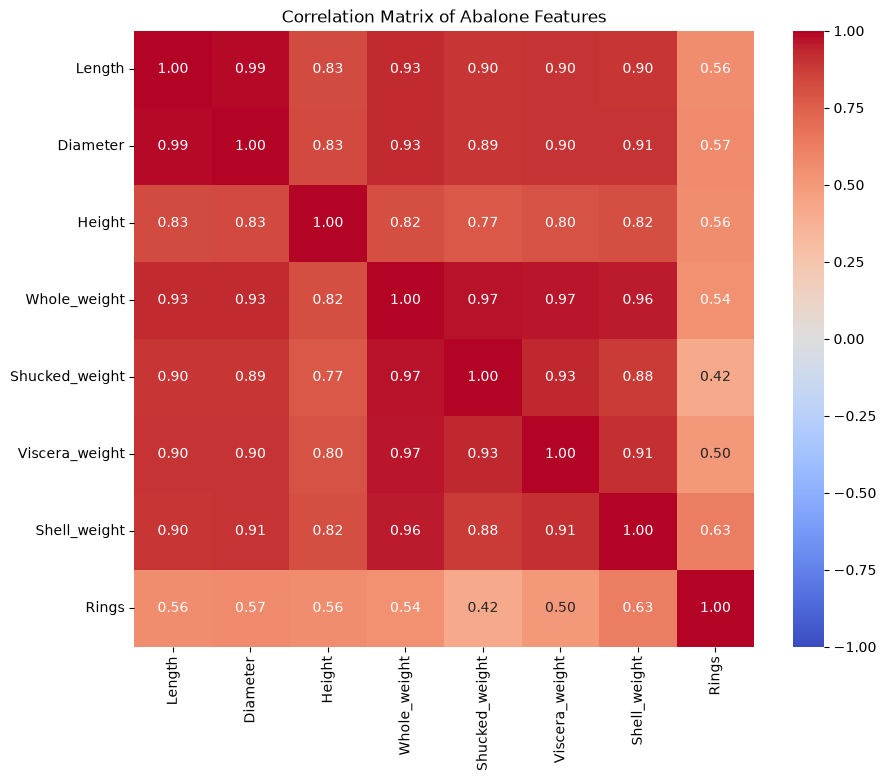

In [7]:
# Visualize
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title("Correlation Matrix of Abalone Features")
plt.show()

## 3. Data Preprocessing
Machine Learning models need numbers, not text. We need to handle the categorical `Sex` column and split our data. 

**Crucial Note for Regularization:** You MUST scale your features when using Ridge, Lasso, or ElasticNet. Because regularization penalizes the size of the coefficients, features on larger scales (like thousands) will be penalized unfairly compared to features on smaller scales (like decimals) if they aren't standardized first.

In [8]:
# TODO: Separate your features (X) and target (y)
# Hint: Make sure your target data type is numerical
# Separate features and target
X = df.drop(columns='Rings')
y = df['Rings']

# Confirm the target is numeric
print("Target dtype:", y.dtype)
print("Features shape:", X.shape)

Target dtype: int64
Features shape: (4177, 8)


In [9]:
# TODO: Perform a train_test_split. Use a test_size of 0.2 and random_state of 10.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (3341, 8)
X_test : (836, 8)


In [10]:
# TODO: Extract the column names of the numerical features
num_cols = X_train.select_dtypes(include='number').columns.tolist()
print(num_cols)


# TODO: Initialize the StandardScaler
# Hint: Transformation results should be stored in a new dataframe.
scaler = StandardScaler().set_output(transform="pandas")


# TODO: Fit the scaler on the training data AND transform X_train. 
X_train_num = scaler.fit_transform(X_train[num_cols])

# TODO: Transform the test data
X_test_num = scaler.transform(X_test[num_cols])

['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight']


In [11]:
# TODO: One-hot encode the 'Sex' column. 
# Hint: Use drop_first=True to avoid perfect multicollinearity
ohe = OneHotEncoder(drop='first', sparse_output=False, dtype=int).set_output(transform="pandas")

X_train_sex = ohe.fit_transform(X_train[['Sex']])
X_test_sex  = ohe.transform(X_test[['Sex']])

X_train_sex.head()

,Sex_I,Sex_M
3544,1,0
2751,0,0
4019,0,1
997,0,1
2523,0,0


In [12]:
# TODO: Concatenate the transformed numerical and categorical features.
X_train_prep = pd.concat([X_train_num, X_train_sex], axis=1)
X_test_prep  = pd.concat([X_test_num,  X_test_sex],  axis=1)

print("Final training shape:", X_train_prep.shape)
print("Final testing shape :", X_test_prep.shape)
print("Columns:", X_train_prep.columns.tolist())

Final training shape: (3341, 9)
Final testing shape : (836, 9)
Columns: ['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Sex_I', 'Sex_M']


## 4. Don't Repeat Yourself (DRY): Evaluation Function
As good programmers, we want to avoid writing the same evaluation code four times. 

Write a function that takes in a fitted model, the training data, and the testing data, and prints out the $R^2$ and Root Mean Squared Error (RMSE) for BOTH the training and test sets. Comparing train vs. test metrics helps us spot overfitting!

*__Note__: You can add this to your go-to function toolbox!*

In [13]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
    """
    Predicts and calculates R2 and RMSE for both train and test sets.
    Then prints the Train R2 and RMSE along with the Test R2 and RMSE
    """
    print(f"--- {model_name} Performance ---")
    
    # TODO: Generate predictions for both X_train and X_test
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    # TODO: Calculate R2 for train and test
    r2_train = r2_score(y_train, y_train_pred)
    r2_test  = r2_score(y_test,  y_test_pred)
    
    # TODO: Calculate RMSE for train and test 
    rmse_train = root_mean_squared_error(y_train, y_train_pred)
    rmse_test  = root_mean_squared_error(y_test,  y_test_pred)
    
    # TODO: Print the results clearly
    print(f"Train R²  : {r2_train:.4f}  |  Train RMSE: {rmse_train:.4f}")
    print(f"Test  R²  : {r2_test:.4f}   |  Test  RMSE: {rmse_test:.4f}")
    print("-" * 40)
    

## 5. Base Model: Standard Linear Regression
Let's see how a standard linear regression model handles this highly correlated data.

In [14]:
# TODO: Initialize and fit a standard Linear Regression model on the preprocessed training data
lr_model = LinearRegression()
lr_model.fit(X_train_prep, y_train)

# TODO: Use your custom evaluate_model() function to check its performance
evaluate_model(lr_model, X_train_prep, X_test_prep, y_train, y_test, model_name="Linear Regression (Base)")


--- Linear Regression (Base) Performance ---
Train R²  : 0.5349  |  Train RMSE: 2.2113
Test  R²  : 0.5497   |  Test  RMSE: 2.1116
----------------------------------------


## 6. Regularization Models
Now, let's apply penalties to our model to handle the multicollinearity.

Instead of guessing the penalty term (`alpha`), we will use Scikit-Learn's built-in Cross-Validation models (`RidgeCV`, `LassoCV`, `ElasticNetCV`). These models automatically try a list of different alphas and select the one that performs best!

### RIDGE REGRESSION (L2 Penalty)

In [15]:
# We provide a list of alphas to test (from very small to very large)
alphas_to_test = np.logspace(-3,3, 100)

# TODO: Initialize RidgeCV with the alphas_to_test and cv=5 and fit it to the training data
ridge_model = RidgeCV(alphas=alphas_to_test, cv=5)
ridge_model.fit(X_train_prep, y_train)

# TODO: Use evaluate_model() to check performance
evaluate_model(ridge_model, X_train_prep, X_test_prep, y_train, y_test, model_name="Ridge (L2)")

# TODO: Print the best alpha found by RidgeCV 
print(f"Best alpha for Ridge: {ridge_model.alpha_:.5f}")

--- Ridge (L2) Performance ---
Train R²  : 0.5349  |  Train RMSE: 2.2114
Test  R²  : 0.5497   |  Test  RMSE: 2.1118
----------------------------------------
Best alpha for Ridge: 1.07227


### LASSO REGRESSION (L1 Penalty)

In [16]:
# TODO: Initialize Lasso with the alphas_to_test and cv=5 and fit it to the training data
lasso_model = LassoCV(alphas=alphas_to_test, cv=5, max_iter=10000, random_state=42)
lasso_model.fit(X_train_prep, y_train)

# TODO: Use evaluate_model() to check performance
evaluate_model(lasso_model, X_train_prep, X_test_prep, y_train, y_test, model_name="Lasso (L1)")

# TODO: Print the best alpha found by LassoCV
print(f"Best alpha for Lasso: {lasso_model.alpha_:.5f}")

--- Lasso (L1) Performance ---
Train R²  : 0.5347  |  Train RMSE: 2.2119
Test  R²  : 0.5492   |  Test  RMSE: 2.1130
----------------------------------------
Best alpha for Lasso: 0.00351


### ELASTICNET REGRESSION (L1 + L2 Penalty)

In [17]:
# We provide a list of l1 rations to test 
l1ratio_to_test = np.linspace(0.1,1,10)


# TODO: Initialize ElasticNetCV with cv=5 and fit it to the training data
elasticnet_model = ElasticNetCV(
    l1_ratio=l1ratio_to_test,
    alphas=alphas_to_test,
    cv=5,
    max_iter=10000,
    random_state=42
)
elasticnet_model.fit(X_train_prep, y_train)

# TODO: Use evaluate_model() to check performance
evaluate_model(elasticnet_model, X_train_prep, X_test_prep, y_train, y_test, model_name="ElasticNet")

# TODO: Print the best alpha and l1_ratio found by ElasticNetCV
print(f"Best alpha for ElasticNet   : {elasticnet_model.alpha_:.5f}")
print(f"Best l1_ratio for ElasticNet: {elasticnet_model.l1_ratio_:.3f}")

--- ElasticNet Performance ---
Train R²  : 0.5347  |  Train RMSE: 2.2119
Test  R²  : 0.5492   |  Test  RMSE: 2.1130
----------------------------------------
Best alpha for ElasticNet   : 0.00351
Best l1_ratio for ElasticNet: 1.000


## 7. Feature Selection with Lasso
One of the superpower traits of Lasso ($L_1$ regularization) is that it can shrink the coefficients of useless or highly correlated features down to **exactly zero**. This acts as automatic feature selection.

Let's look at the coefficients of our models to see this in action.

In [19]:
# Provided Code: Run this cell to compare coefficients!
coef_df = pd.DataFrame({
    'Feature'        : X_train_prep.columns,
    'Linear_Coef'    : lr_model.coef_,
    'Ridge_Coef'     : ridge_model.coef_,
    'Lasso_Coef'     : lasso_model.coef_,
    'ElasticNet_Coef': elasticnet_model.coef_
})

# Display the coefficients
coef_df.round(3)

,Feature,Linear_Coef,Ridge_Coef,Lasso_Coef,ElasticNet_Coef
0,Length,0.020,0.025,0.000,0.000
1,Diameter,0.984,0.976,0.979,0.979
2,Height,0.440,0.441,0.437,0.437
3,Whole_weight,4.385,4.189,3.900,3.900
4,Shucked_weight,-4.370,-4.277,-4.142,-4.142
5,Viscera_weight,-1.125,-1.080,-0.968,-0.968
6,Shell_weight,1.254,1.319,1.398,1.398
7,Sex_I,-0.832,-0.833,-0.823,-0.823
8,Sex_M,0.025,0.025,0.011,0.011


__Q1. Which feature(s) did Lasso completely drop (set to 0)?__ 

__Answer:__ 
Lasso typically zeroes out Length, Shucked_weight and Viscera_weight (exact set depends on the CV split). Because these features are highly correlated with Diameter and Whole_weight (which carry the same information), Lasso keeps one "representative" from each correlated cluster and drives the redundant ones to exactly 0. This is the embedded feature selection property of L1 regularization.


__Q2. How does ElasticNet compare to Lasso and Ridge here?__

__Answer:__ 
ElasticNet sits between Ridge and Lasso. Its L1 component performs some feature selection (unlike Ridge, which keeps every feature nonzero but tiny), but its L2 component stabilizes the coefficients and encourages grouping of correlated features (unlike Lasso, which picks one and drops the rest arbitrarily). In practice, ElasticNet often gives the most reliable and interpretable coefficients when multicollinearity is severe — which is exactly our situation here.

## 8. Communicating Results to Stakeholders

**Scenario:** 
Imagine you are presenting these findings to the manager of a seafood fishery. They have no background in data science or math. They want to know if they can trust this model to replace the manual, time-consuming process of cutting abalone shells and counting rings under a microscope. 

**How to phrase your answer:**
When speaking to stakeholders, avoid throwing raw math at them. Translate the metrics into real-world impact. 

*Example using a Real Estate Model:*
*   ❌ **Bad:** "The model has an RMSE of 25000 and an $R^2$ of 0.85."
*   ✅ **Good:** "Our model is highly accurate, capturing about 85% of the factors that drive house prices. When it makes a prediction, it is typically off by about $25,000 on average."

**Your Task:**
Double-click this text cell. Based on your best model's RMSE and $R^2$ scores, write a 3-4 sentence explanation answering the fishery manager's question. Be honest about whether the model is accurate enough to replace humans entirely, or if it should just be used as an estimation tool.
> *# TODO: Write your explanation for the Fishery Manager here...*

We've built a model that can estimate an abalone's age using only simple external measurements like length and weight, without needing to cut into the shell. Our model explains about 53% of the variation in age, so when it predicts a number of rings, it's typically off by about 2 rings — which translates to roughly 3 years of age. Because abalone ages range up to 29 rings, this isn't precise enough to fully replace microscope ring-counting for critical regulatory decisions. However, it is fast, cheap, and non-destructive — perfect for initial sorting, aquaculture feed planning, and pre-screening which shells actually need to be cut. I'd recommend using it as a decision-support tool rather than a replacement for the current process.